# Visualize High-Frequency Components on Token Graphs

This notebook shows the nodewise distribution of high-frequency hidden-state energy for representative constant and chaotic logistic-map ($r = 4.0$) inputs at the final layer of Llama-3.2-3B with $N = 500$. Graph construction, layout, and edge rendering follow the setup used in the main token-graph experiments. Node colors indicate high-frequency energy as a percentage of total hidden-state energy.


Set imports, the 500-token analysis window, relative cache and figure paths, and the main token-graph figure styles with extra footer space for the HF colorbar.


In [1]:
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS  # Relative to the 1,000-token reference length
CONTEXT_DISPLAY_LABEL = f'{ANALYSIS_CONTEXT_TOKENS} tokens'
PROCESSED_DATA_DIR = Path('cache')
FIGURE_OUTPUT_DIR = Path('figures')

# Attention-graph style
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_NODE_SIZE = 18
RGB_GRAPH_DELIMITER_SIZE = 24
RGB_GRAPH_NODE_SIZE_FLOOR = 8
RGB_GRAPH_DELIMITER_SIZE_FLOOR = 10
RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE = False
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_STYLE_BINS = 20
LABEL_TOKEN_MARKERS = True
TOKEN_MARKER_LABELS_ONE_BASED = np.array([1, 100, 200, 300, 400, ANALYSIS_CONTEXT_TOKENS], dtype=int)
RGB_GRAPH_X_MARGIN = 0.04
RGB_GRAPH_Y_MARGIN = 0.10
# Panel layout with room for the legend and shared colorbar.
FIGURE_SIZE = (6.8, 5.2)
DISPLAY_DPI = 150
FIGURE_DPI = 300
SUBPLOT_ADJUST = dict(left=0.01, right=0.99, bottom=0.29, top=0.94, wspace=0.0)
GRAPH_LEGEND_ANCHOR = (0.5, 0.16)
GRAPH_LEGEND_FONT_SIZE = 11.0
HF_COLORBAR_BOUNDS = [0.25, 0.075, 0.50, 0.022]
HF_COLORBAR_FONT_SIZE = 11.5
SAVEFIG_PAD_INCHES = 0.005
FONT_SIZE_SCALE = 1.10
PANEL_TITLE_FONT_SIZE = 14.6
PANEL_TITLE_Y_OFFSET = 0.001

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['font.size'] = plt.rcParamsDefault['font.size'] * FONT_SIZE_SCALE
plt.rcParams['savefig.dpi'] = FIGURE_DPI
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# Default HF band: the highest 50% of combinatorial-Laplacian eigenvalues.
HF_TAIL_FRACTIONS = np.asarray([0.50], dtype=np.float64)
HF_TAIL_FRACTIONS_TO_PLOT = HF_TAIL_FRACTIONS.copy()
HF_SCHEMA_VERSION = "hidden_state_hf_node_energy_combinatorial_v1"
HF_DATA_ARRAY_KEYS = (
    "hf_schema_version", "hf_tail_fractions", "hf_tail_mode_counts",
    "hf_tail_cutoffs", "hf_node_energy", "hidden_signal_total_energy",
    "hfer_tail_energy",
)

# Shared linear percentage scale.
FINAL_LAYER_INDEX = 28
HF_COLOR_VMAX = 0.28  # Shared contribution scale; None uses the maximum across displayed data.
HF_CMAP = "Reds"  # Pale to dark red: low to high HF energy.
HF_COLORBAR_LABEL = "HF energy contribution (% of total)"


Validate HF energy accounting and define a scalar color mapping shared across the displayed graphs. Colors use $c_i=100 e_i/\|X\|_F^2$, so summing the node contributions gives $100\,\mathrm{HFER}$ (a percentage). Here $e_i$ is reconstructed HF energy from the default top-50% combinatorial-Laplacian modes. The full unthresholded graph enters this calculation.


In [2]:
def validate_hf_arrays(data, completed_layers=None):
    """Reject stale/incomplete HF caches and verify their energy accounting."""
    missing = [key for key in HF_DATA_ARRAY_KEYS if key not in data]
    if missing:
        raise ValueError(f"Missing HF arrays: {missing}. Run the companion Generate notebook.")
    if str(np.asarray(data["hf_schema_version"]).item()) != HF_SCHEMA_VERSION:
        raise ValueError("Incompatible HF cache schema; regenerate this archive.")
    fractions = np.asarray(data["hf_tail_fractions"], dtype=float)
    if fractions.shape != HF_TAIL_FRACTIONS.shape or not np.allclose(fractions, HF_TAIL_FRACTIONS):
        raise ValueError("Cached HF cutoffs differ from HF_TAIL_FRACTIONS.")
    n_layers = len(data["layer_indices"])
    n_nodes = len(data["is_delimiter"])
    counts = np.asarray([int(round(float(q) * n_nodes)) for q in fractions], dtype=np.int64)
    expected = {
        "hf_node_energy": (n_layers, len(fractions), n_nodes),
        "hidden_signal_total_energy": (n_layers,),
        "hfer_tail_energy": (n_layers, len(fractions)),
    }
    for key, shape in expected.items():
        if np.asarray(data[key]).shape != shape:
            raise ValueError(f"Invalid {key} shape: expected {shape}.")
    if not np.array_equal(data["hf_tail_mode_counts"], counts):
        raise ValueError("HF mode counts do not match the graph size.")
    if not np.array_equal(data["hf_tail_cutoffs"], n_nodes - counts):
        raise ValueError("HF cutoff indices do not match the graph size.")
    selected = np.ones(n_layers, dtype=bool) if completed_layers is None else np.asarray(completed_layers, dtype=bool)
    if selected.shape != (n_layers,):
        raise ValueError("Invalid completed-layer mask.")
    if not np.any(selected):
        return
    node_energy = np.asarray(data["hf_node_energy"], dtype=float)[selected]
    total = np.asarray(data["hidden_signal_total_energy"], dtype=float)[selected]
    hfer = np.asarray(data["hfer_tail_energy"], dtype=float)[selected]
    if not (np.isfinite(node_energy).all() and np.isfinite(total).all() and np.isfinite(hfer).all()):
        raise ValueError("Nonfinite HF energy in a completed layer.")
    if np.any(node_energy < 0) or np.any(total <= 0) or np.any(hfer < 0) or np.any(hfer > 1 + 1e-8):
        raise ValueError("Invalid HF energy values.")
    if not np.allclose(node_energy.sum(axis=-1) / total[:, None], hfer, rtol=1e-7, atol=1e-10):
        raise ValueError("Node-energy sum does not reproduce HFER.")


def hf_tail_index(processed_data, tail_fraction):
    matches = np.flatnonzero(np.isclose(processed_data["hf_tail_fractions"], float(tail_fraction)))
    if matches.size != 1:
        raise ValueError(f"HF cutoff {tail_fraction:g} is unavailable in this archive.")
    return int(matches[0])


def normalized_hf_node_energy(processed_data, offset, tail_fraction):
    tail_idx = hf_tail_index(processed_data, tail_fraction)
    energy = np.asarray(processed_data["hf_node_energy"], dtype=float)[offset, tail_idx]
    total = float(processed_data["hidden_signal_total_energy"][offset])
    # Sum over nodes is 100 * HFER: each node contributes a percentage of total energy.
    return 100.0 * energy / total


def shared_hf_color_norm():
    """Pool the displayed final-layer scores, with an optional explicit upper limit."""
    maximum = 0.0
    for data_name in DATA_ORDER:
        processed_data = load_processed_graph_data(data_name)
        offset = layer_offset(processed_data, FINAL_LAYER_INDEX)
        for tail_fraction in HF_TAIL_FRACTIONS_TO_PLOT:
            values = normalized_hf_node_energy(processed_data, offset, tail_fraction)
            maximum = max(maximum, float(np.max(values)))
    vmax = (maximum if maximum > 0 else 1.0) if HF_COLOR_VMAX is None else float(HF_COLOR_VMAX)
    if not np.isfinite(vmax) or vmax <= 0:
        raise ValueError('HF_COLOR_VMAX must be positive and finite, or None.')
    return mpl.colors.Normalize(vmin=0.0, vmax=vmax)


def hf_node_colors(processed_data, offset, tail_fraction, color_norm):
    values = normalized_hf_node_energy(processed_data, offset, tail_fraction)
    return np.asarray(plt.get_cmap(HF_CMAP)(color_norm(values))[:, :3], dtype=np.float32)


def add_hf_colorbar(fig, color_norm, rect, fontsize=8):
    cax = fig.add_axes(rect)
    mappable = mpl.cm.ScalarMappable(norm=color_norm, cmap=HF_CMAP)
    colorbar = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    if np.isclose(color_norm.vmax, 0.28):
        colorbar.set_ticks([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.28])
    colorbar.ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f'))
    colorbar.set_label(HF_COLORBAR_LABEL, fontsize=fontsize, labelpad=2)
    colorbar.ax.tick_params(labelsize=fontsize - 1, length=2, pad=2)
    return colorbar


In [3]:
# Input order and labels
DATA_ORDER = ['Constant 500', 'Logistic r=4.0']

DATA_TITLE_OVERRIDES = {'Constant 500': 'Constant sequence'}
DATA_TITLE_SUFFIXES = {'Logistic r=4.0': 'chaotic'}

GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'layout_positions',
    'svd_projection_coords',
    'svd_cumulative_energy_ratio',
    'is_delimiter',
)


GRAPH_DATA_ARRAY_KEYS += HF_DATA_ARRAY_KEYS


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_display_label(num_tokens=ANALYSIS_CONTEXT_TOKENS):
    return f'{int(num_tokens)} tokens'


def context_fraction_label(frac):
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


Load and validate the cached graph/HF archives, including the 500-token analysis window.


In [4]:
def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    extra = sorted(set(processed_data) - set(GRAPH_DATA_ARRAY_KEYS))
    if extra:
        raise KeyError(f'{path} contains unexpected arrays: {extra}')
    validate_hf_arrays(processed_data)
    if len(processed_data['is_delimiter']) != ANALYSIS_CONTEXT_TOKENS:
        raise ValueError(f'{path} does not contain {ANALYSIS_CONTEXT_TOKENS} token nodes.')
    return processed_data


def check_processed_graph_data(data_names=DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)


Draw attention-weighted edges, numeric/separator token nodes, and labeled input-position markers.


In [5]:
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)


def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]

    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx

    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


def token_marker_indices_and_labels(n, marker_labels_one_based=TOKEN_MARKER_LABELS_ONE_BASED):
    marker_labels = np.asarray(marker_labels_one_based, dtype=int)
    valid = (marker_labels >= 1) & (marker_labels <= int(n))
    marker_labels = marker_labels[valid]
    marker_indices = marker_labels - 1
    return marker_indices.astype(int), marker_labels.astype(int)


def annotate_token_position_markers(
    ax,
    x,
    y,
    marker_indices,
    marker_labels=None,
    label_markers=LABEL_TOKEN_MARKERS,
    label_position_overrides=None,
):
    marker_indices = np.asarray(marker_indices, dtype=int)
    if marker_labels is None:
        marker_labels = marker_indices + 1
    marker_labels = np.asarray(marker_labels, dtype=int)
    if marker_indices.size == 0:
        return

    valid = (marker_indices >= 0) & (marker_indices < len(x))
    marker_indices = marker_indices[valid]
    marker_labels = marker_labels[valid]
    if marker_indices.size == 0:
        return

    ax.scatter(
        x[marker_indices],
        y[marker_indices],
        s=70,
        facecolors='white',
        edgecolors='#111111',
        linewidths=1.35,
        alpha=0.98,
        zorder=7,
        clip_on=False,
    )

    if not label_markers:
        return

    label_position_overrides = label_position_overrides or {}
    for idx, label in zip(marker_indices, marker_labels):
        label_style = dict(xytext=(3, 3), ha='left', va='bottom')
        label_style.update(label_position_overrides.get(int(label), {}))
        ax.annotate(
            f'{int(label)}',
            (x[idx], y[idx]),
            xytext=label_style['xytext'],
            textcoords='offset points',
            fontsize=7.35 * FONT_SIZE_SCALE,
            fontweight='bold',
            ha=label_style['ha'],
            va=label_style['va'],
            color='#000000',
            bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='#111111', linewidth=0.35, alpha=0.92),
            zorder=8,
            annotation_clip=False,
            clip_on=False,
        )


def draw_processed_layer_on_ax(
    ax,
    W,
    xy,
    rgb,
    is_delimiter,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
    edge_weight_limits=None,
    label_token_markers=LABEL_TOKEN_MARKERS,
    marker_label_position_overrides=None,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    rgb = np.asarray(rgb, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)

    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    rgb = np.clip(rgb[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=max_edges,
        threshold_factor=edge_threshold_factor,
    )

    if RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE and n > 1:
        ax.plot(x, y, color='#BBBBBB', linewidth=0.6, alpha=0.5, zorder=1)

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(RGB_GRAPH_NODE_SIZE_FLOOR), RGB_GRAPH_NODE_SIZE * 0.8),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )

    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(RGB_GRAPH_DELIMITER_SIZE_FLOOR), RGB_GRAPH_DELIMITER_SIZE * 0.8),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )

    if label_token_markers:
        marker_indices, marker_labels = token_marker_indices_and_labels(n)
        annotate_token_position_markers(
            ax,
            x,
            y,
            marker_indices,
            marker_labels=marker_labels,
            label_markers=label_token_markers,
            label_position_overrides=marker_label_position_overrides,
        )

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}


In [6]:
def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def add_row_aligned_panel_titles(fig, axes, titles, ncols=2):
    fig.canvas.draw()
    for row_start in range(0, len(titles), ncols):
        row_axes = axes[row_start:row_start + ncols]
        row_titles = titles[row_start:row_start + ncols]
        title_y = row_axes[0].get_position().y1 + PANEL_TITLE_Y_OFFSET
        for ax, title in zip(row_axes, row_titles):
            pos = ax.get_position()
            fig.text(
                pos.x0 + 0.5 * pos.width,
                title_y,
                title,
                ha='center',
                va='bottom',
                fontsize=PANEL_TITLE_FONT_SIZE,
            )


Assemble the final-layer $1 \times 2$ appendix figure with shared edge styles, a token legend, and a common HF colorbar.


In [7]:
def collect_layer_panel_data_for_global_edge_norm(
    layer_index,
    tail_fraction,
    color_norm,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    panel_data = []
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
        offset = layer_offset(processed_data, layer_index)

        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        layout_positions = np.asarray(processed_data['layout_positions'], dtype=np.float32)[offset]
        rgb_colors = hf_node_colors(processed_data, offset, tail_fraction, color_norm)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        _, _, w_edges = select_top_edges(
            Wbar,
            max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
            threshold_factor=edge_threshold_factor,
        )
        if w_edges.size:
            all_edge_weights.append(w_edges)

        panel_data.append(
            dict(
                data_name=data_name,
                last_layer_index=int(layer_indices[-1]),
                Wbar=Wbar,
                layout_positions=layout_positions,
                rgb_colors=rgb_colors,
                is_delimiter=is_delimiter,
            )
        )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits


def add_layerwise_graph_figure_key(fig):
    marker_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=7.2
        ),
        Line2D(
            [0], [0], marker='^', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=7.8
        ),
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='white',
            markeredgecolor='#111111', markeredgewidth=1.3, markersize=8.3
        ),
        Line2D(
            [0, 1], [0, 0], color='#444444', linewidth=2.5, alpha=0.80
        ),
    ]
    marker_labels = [
        'Numeric-token nodes',
        'Separator-token nodes',
        'Input position markers',
        'Attention-weighted edges',
    ]
    fig.legend(
        handles=marker_handles,
        labels=marker_labels,
        loc='lower center',
        bbox_to_anchor=GRAPH_LEGEND_ANCHOR,
        ncol=2,
        frameon=True,
        fontsize=GRAPH_LEGEND_FONT_SIZE,
        handlelength=1.05,
        handletextpad=0.35,
        columnspacing=1.2,
        borderaxespad=0.0,
    )


def plot_layer_across_inputs_global_edge_norm(
    layer_index,
    tail_fraction,
    color_norm,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=False,
    save_filename='last_layer_hf_energy.pdf',
    show=True,
    label_token_markers=LABEL_TOKEN_MARKERS,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    panel_data, edge_weight_limits = collect_layer_panel_data_for_global_edge_norm(
        layer_index=layer_index,
        tail_fraction=tail_fraction,
        color_norm=color_norm,
        frac=frac,
        data_names=data_names,
        data_dir=data_dir,
        edge_threshold_factor=edge_threshold_factor,
    )

    if len(panel_data) != 2:
        raise ValueError('The 1 x 2 figure requires exactly two selected inputs.')
    fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE, dpi=DISPLAY_DPI)
    axes = np.asarray(axes).ravel()
    panel_titles = [panel_title(payload['data_name']) for payload in panel_data]

    for ax, payload in zip(axes, panel_data):
        draw_processed_layer_on_ax(
            ax,
            payload['Wbar'],
            payload['layout_positions'],
            payload['rgb_colors'],
            payload['is_delimiter'],
            edge_weight_limits=edge_weight_limits,
            label_token_markers=label_token_markers,
            edge_threshold_factor=edge_threshold_factor,
        )

    for ax in axes[len(panel_data):]:
        ax.axis('off')

    fig.subplots_adjust(**SUBPLOT_ADJUST)
    add_row_aligned_panel_titles(fig, axes, panel_titles, ncols=2)
    add_layerwise_graph_figure_key(fig)

    add_hf_colorbar(fig, color_norm, HF_COLORBAR_BOUNDS, fontsize=HF_COLORBAR_FONT_SIZE)
    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        save_path = figure_output_dir / str(save_filename)
        if save_path.suffix.lower() != '.pdf':
            raise ValueError('Save the figure as a PDF.')
        fig.savefig(save_path, bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)
        print(f'Saved {save_path}')

    if show:
        plt.show()

    return fig


Validate the caches, display the 1 × 2 final-layer top-50% HF-energy-contribution comparison, and save the PDF in `figures/`.


Final-layer HF energy contribution (% of total; both inputs): 0 to 0.28


Saved figures/last_layer_hf_energy.pdf


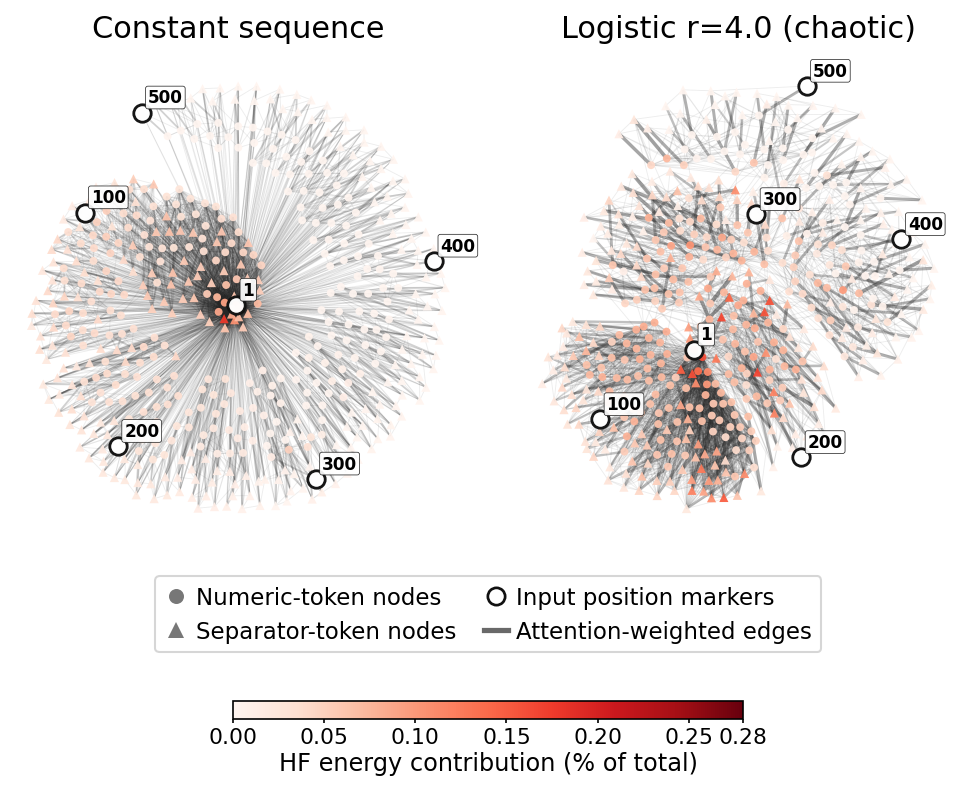

In [8]:
check_processed_graph_data()
LAYER_INDEX = FINAL_LAYER_INDEX
COLOR_NORM = shared_hf_color_norm()
print(f"Final-layer HF energy contribution (% of total; both inputs): {COLOR_NORM.vmin:.10g} to {COLOR_NORM.vmax:.10g}")
fig = plot_layer_across_inputs_global_edge_norm(
    layer_index=LAYER_INDEX,
    tail_fraction=float(HF_TAIL_FRACTIONS[0]),
    color_norm=COLOR_NORM,
    frac=CONTEXT_FRAC,
    save=True,
    save_filename="last_layer_hf_energy.pdf",
    show=True,
)
plt.close(fig)
